# When the Leaderboard Flips: Perturbation-Dependent Ranking in LLM Evaluation
### M20 Initial Report — Capstone Part 1

**Research question.** Can characteristics of LLMs, tasks, and controlled evaluation conditions predict when performance remains stable or changes, including changes in relative model ranking?

This report analyzes a frozen Block-A experiment containing **1,000 observations**: 50 source questions × 5 evaluation conditions × 4 LLMs. Acquisition, prompt identity, scoring, and the full experimental grid were independently audited before analysis.

## 1. Business and research understanding

Leaderboard averages are commonly used to compare candidate models, but deployment decisions depend on whether those comparisons remain stable when prompts are reformatted, paraphrased, repositioned, or supplied with irrelevant benign context. A model-selection process that is sensitive to small evaluation changes can produce brittle decisions even when average accuracy is high.

The M20 objective is to characterize condition-dependent stability/ranking changes and establish a leakage-safe supervised-learning baseline for predicting response correctness from pre-response information.

## 2. Experimental design and provenance

Two benchmarks are represented: **ARC-Challenge** and **GSM8K**. Block A contains 25 frozen questions from each. Every question is evaluated under five conditions: baseline, formatting change, instruction-position change, irrelevant benign context, and paraphrase. The same frozen question-condition prompt is supplied to all four models.

All 50 Block-A source items passed the predeclared QA gate. Pilot and qualification observations are excluded.

In [1]:
import pandas as pd, numpy as np, hashlib, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from IPython.display import Image, display

DATA="../data/processed/M20_BlockA_4Model_INTEGRATED_AUDITED_ANALYSIS.csv"
df=pd.read_csv(DATA)
print(f"Rows: {len(df):,} | Questions: {df.question_id.nunique()} | Models: {df.model_tag.nunique()} | Conditions: {df.condition.nunique()}")
df.head(3)

Rows: 1,000 | Questions: 50 | Models: 4 | Conditions: 5


,observation_id,master_id,block,question_id,benchmark,condition,prompt,prompt_word_count,prompt_sha256,generation_method,semantic_equivalence_status,semantic_flag,semantic_notes,reference_answer,provider,model_id,phase,phase_attempt,token_budget,started_utc,finished_utc,latency_sec,api_status,finish_reason,raw_response,usage,error,parse_status,parsed_answer,correct,model_tag,correct_reconstructed,score_reconstruction_match,qa_master_id,qa_block,qa_benchmark,qa_source_index,qa_original_question,qa_choices,qa_reference_answer,qa_source_record_sha256,qa_item_quality_status,qa_item_quality_flag,qa_item_quality_notes,correct_int,question_word_count,is_error,split_u,split
0,6203e094df60b4e3887ec9b92ee74cead58b0f7e0f220e...,M20_MASTER_200_v1,A,ARC_MCAS_1998_8_2,ARC-Challenge,baseline,The cell structure that makes a plant cell mor...,40,24c0db244b8dbcf792a705d3d33a926152bbcca0e4debe...,deterministic_template,NOT_APPLICABLE_DETERMINISTIC,NaN,Deterministic perturbation generated from froz...,C,gemini,gemini-3.5-flash-lite,main,1,1200,2026-10-07T19:24:14.841603+00:00,2026-10-07T19:24:15.504038+00:00,0.6622,SUCCESS,NaN,ANSWER: C,cache_tokens_details=None cached_content_token...,NaN,PARSED,C,1,Gemini_3_5_Flash_Lite,1,True,M20_MASTER_200_v1,A,ARC-Challenge,206,The cell structure that makes a plant cell mor...,A. cell membrane.\nB. cytoplasm.\nC. cell wall...,C,5b251ee45e75ca8eee28c847d799acf77b6cb14dac80fa...,VALID,NaN,NaN,1,16,0,0.702904,train
1,1f37a2b25cab3d92aafc54a125ee1b2676cb8a51576e2b...,M20_MASTER_200_v1,A,ARC_MCAS_1998_8_2,ARC-Challenge,formatting,QUESTION\n========\nThe cell structure that ma...,47,bc4419209c64c59eb5276ec7e2fc30af291be2f40036f2...,deterministic_template,NOT_APPLICABLE_DETERMINISTIC,NaN,Deterministic perturbation generated from froz...,C,gemini,gemini-3.5-flash-lite,main,1,1200,2026-10-07T19:24:15.546967+00:00,2026-10-07T19:24:16.387699+00:00,0.8405,SUCCESS,NaN,To determine which cell structure makes a plan...,cache_tokens_details=None cached_content_token...,NaN,PARSED,C,1,Gemini_3_5_Flash_Lite,1,True,M20_MASTER_200_v1,A,ARC-Challenge,206,The cell structure that makes a plant cell mor...,A. cell membrane.\nB. cytoplasm.\nC. cell wall...,C,5b251ee45e75ca8eee28c847d799acf77b6cb14dac80fa...,VALID,NaN,NaN,1,16,0,0.702904,train
2,34509ce16a5406d2107c645269dca887564d2e9383400b...,M20_MASTER_200_v1,A,ARC_MCAS_1998_8_2,ARC-Challenge,instruction_position,Return only the final answer in the form ANSWE...,40,57fc5491da617db0955a9c72c61d353b438ca9d436effb...,deterministic_template,NOT_APPLICABLE_DETERMINISTIC,NaN,Deterministic perturbation generated from froz...,C,gemini,gemini-3.5-flash-lite,main,1,1200,2026-10-07T19:24:16.493072+00:00,2026-10-07T19:24:17.478821+00:00,0.9855,SUCCESS,NaN,To determine which cell structure makes a plan...,cache_tokens_details=None cached_content_token...,NaN,PARSED,C,1,Gemini_3_5_Flash_Lite,1,True,M20_MASTER_200_v1,A,ARC-Challenge,206,The cell structure that makes a plant cell mor...,A. cell membrane.\nB. cytoplasm.\nC. cell wall...,C,5b251ee45e75ca8eee28c847d799acf77b6cb14dac80fa...,VALID,NaN,NaN,1,16,0,0.702904,train


## 3. Integrity, cleaning, and feature engineering

In [2]:
assert len(df)==1000
assert df.observation_id.nunique()==1000
assert df.question_id.nunique()==50
assert df.model_tag.nunique()==4
assert df.condition.nunique()==5
assert df.correct_int.isin([0,1]).all()
assert df.qa_item_quality_status.eq("VALID").all()
assert df.groupby(["question_id","condition"]).model_tag.nunique().eq(4).all()
print("Analysis integrity checks: PASS")
print(pd.crosstab(df.model_tag,df.benchmark))
print(pd.crosstab(df.model_tag,df.condition))

Analysis integrity checks: PASS
benchmark              ARC-Challenge  GSM8K
model_tag                                  
GPT_OSS_120B                     125    125
GPT_OSS_20B                      125    125
Gemini_3_5_Flash_Lite            125    125
Qwen3_8_27B                      125    125
condition              baseline  formatting  ...  irrelevant_context  paraphrase
model_tag                                    ...                                
GPT_OSS_120B                 50          50  ...                  50          50
GPT_OSS_20B                  50          50  ...                  50          50
Gemini_3_5_Flash_Lite        50          50  ...                  50          50
Qwen3_8_27B                  50          50  ...                  50          50

[4 rows x 5 columns]


Engineered pre-response features include prompt word count and original-question word count. Model identity, benchmark, and perturbation condition are categorical predictors. Response text, parsed answer, latency, and correctness-derived variables are excluded from predictive features to avoid post-response leakage.

In [3]:
df[["prompt_word_count","question_word_count"]].describe().round(2)

,prompt_word_count,question_word_count
count,1000.00,1000.00
mean,66.74,34.60
std,18.99,17.73
min,35.00,7.00
25%,53.00,20.00
50%,66.00,30.50
75%,79.00,46.00
max,124.00,82.00


## 4. Exploratory analysis: aggregate and condition-dependent performance

In [4]:
summary=df.groupby("model_tag").correct_int.agg(["count","sum","mean"])
summary["errors"]=summary["count"]-summary["sum"]
summary.rename(columns={"mean":"accuracy"}).sort_values("accuracy",ascending=False)

,count,sum,accuracy,errors
model_tag,,,,
Gemini_3_5_Flash_Lite,250,250,1.000,0
Qwen3_8_27B,250,249,0.996,1
GPT_OSS_20B,250,248,0.992,2
GPT_OSS_120B,250,243,0.972,7


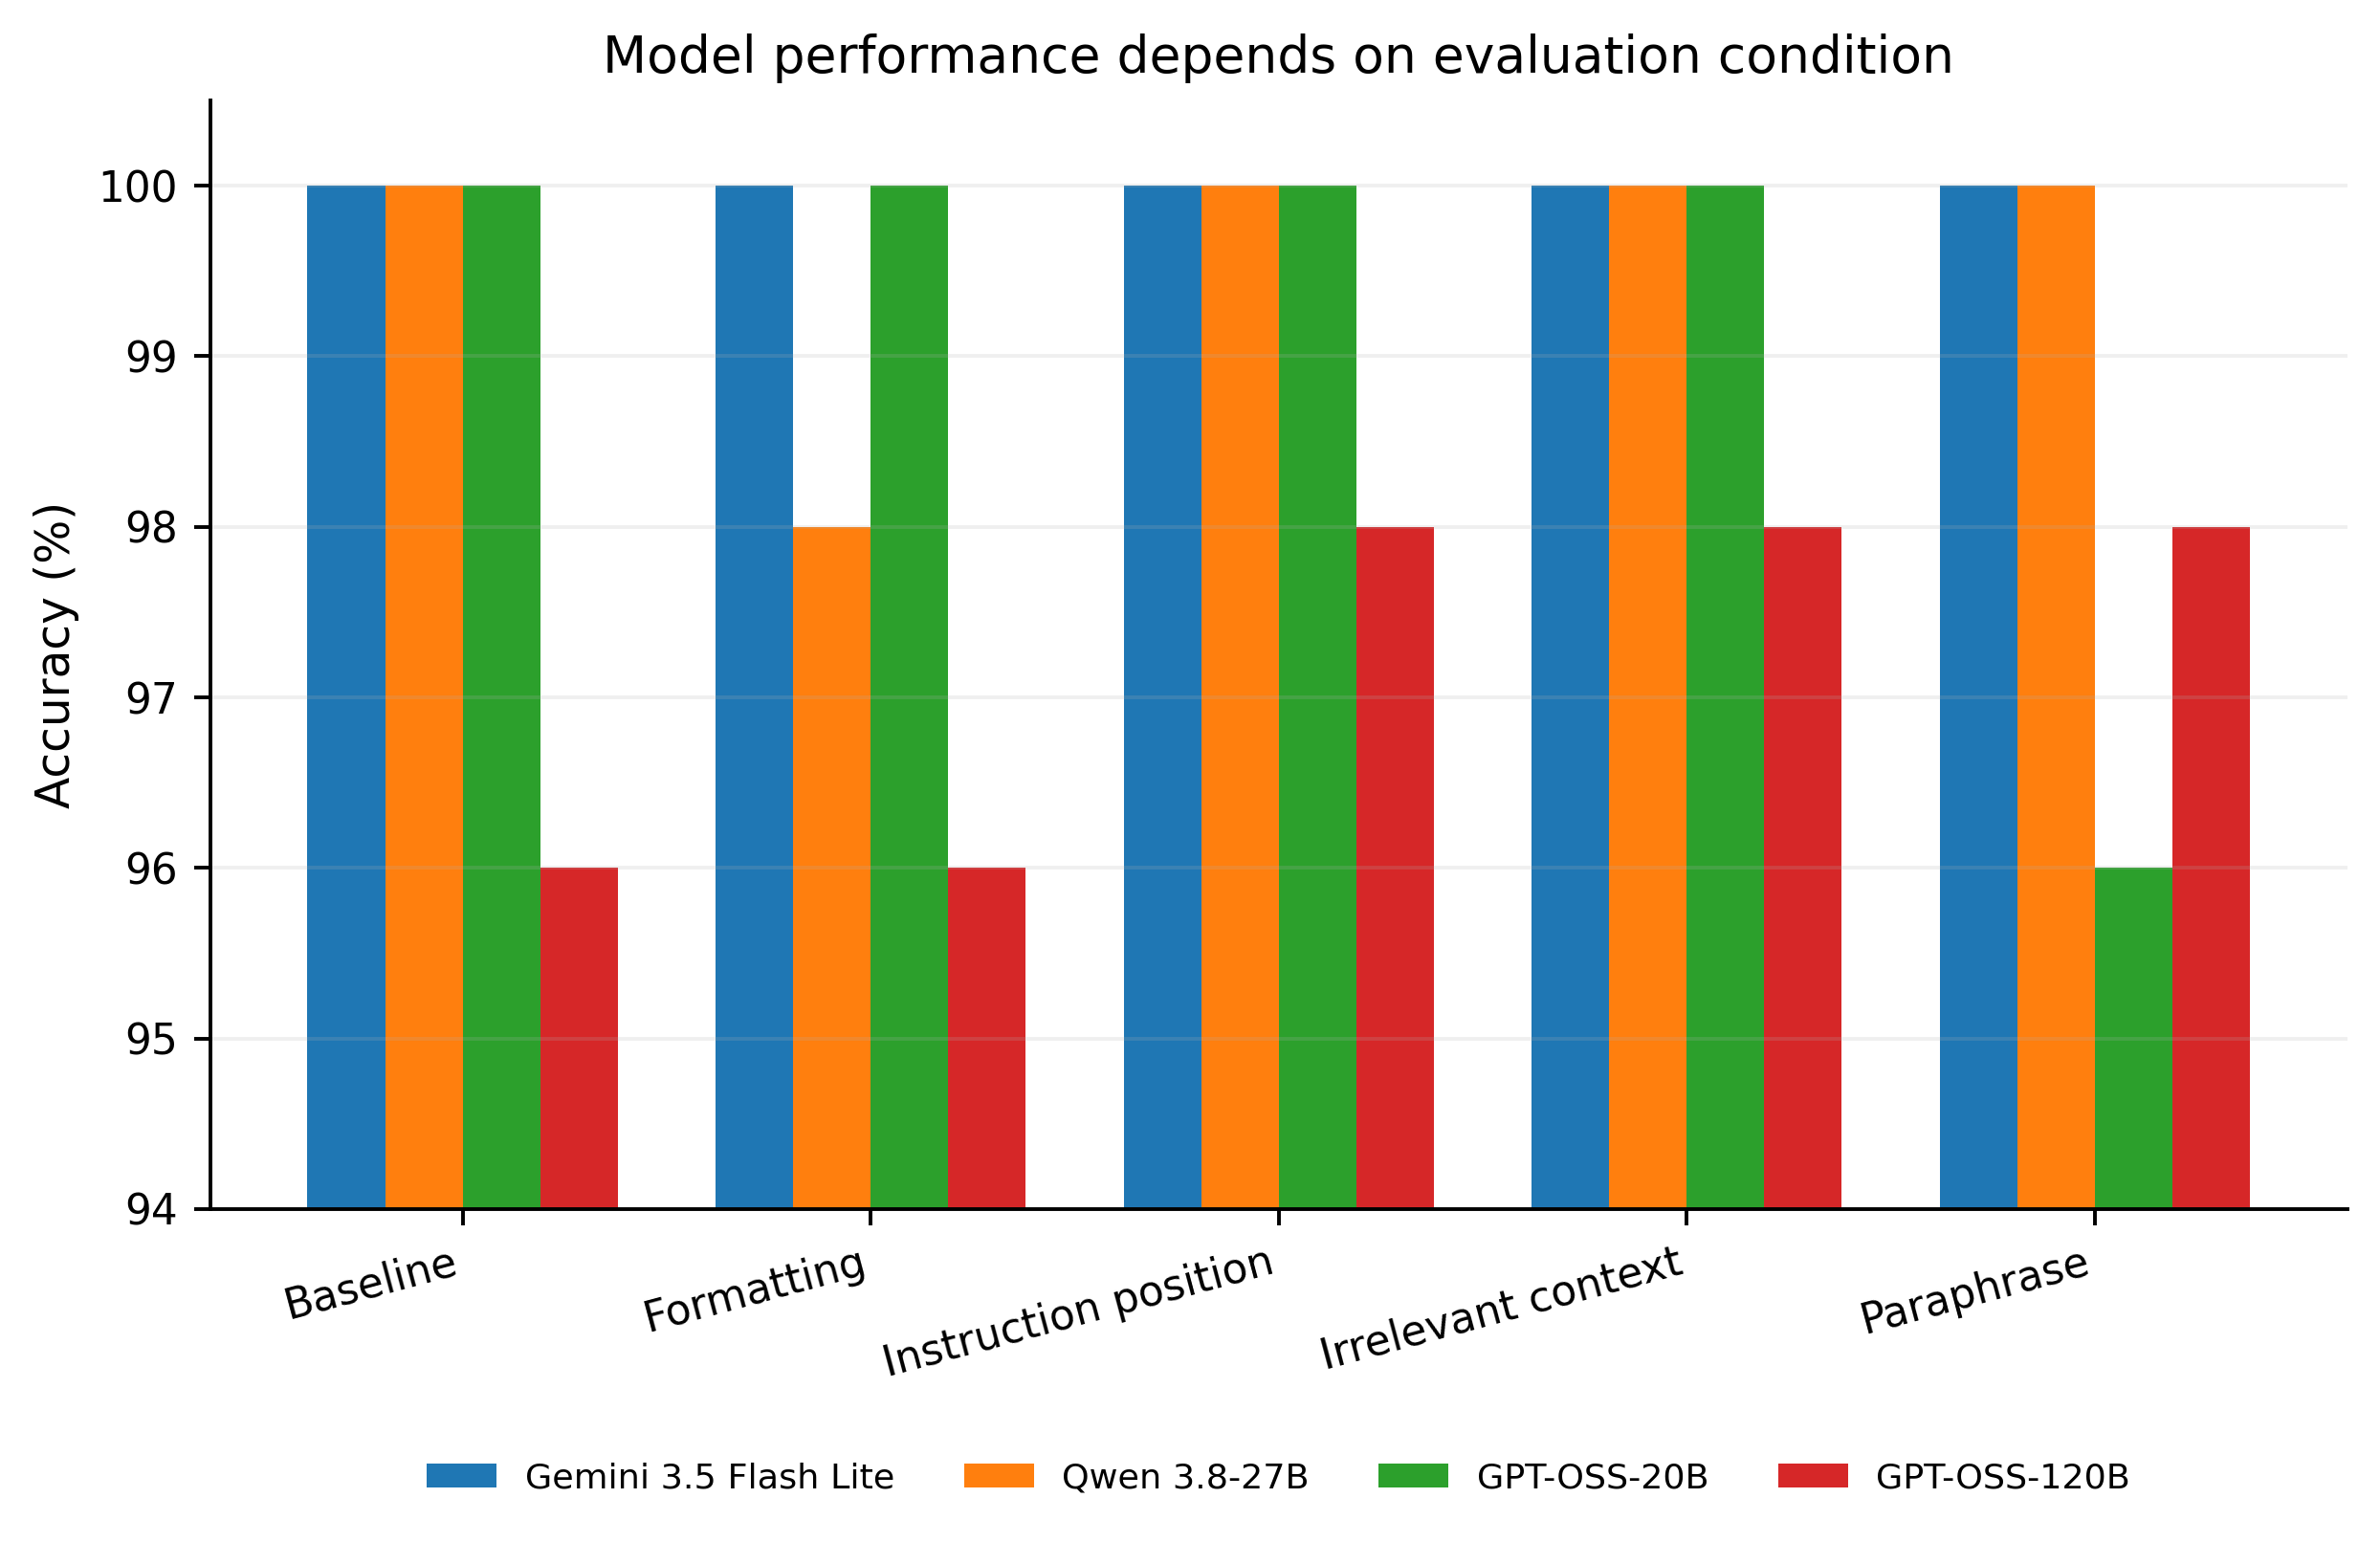

In [5]:
display(Image("../figures/Fig1_condition_dependent_accuracy.png"))

**Figure 1.** Accuracy by model and evaluation condition. The perturbation effect is model dependent rather than a uniform decrease in accuracy.

## 5. Condition-dependent ranking and paired stability

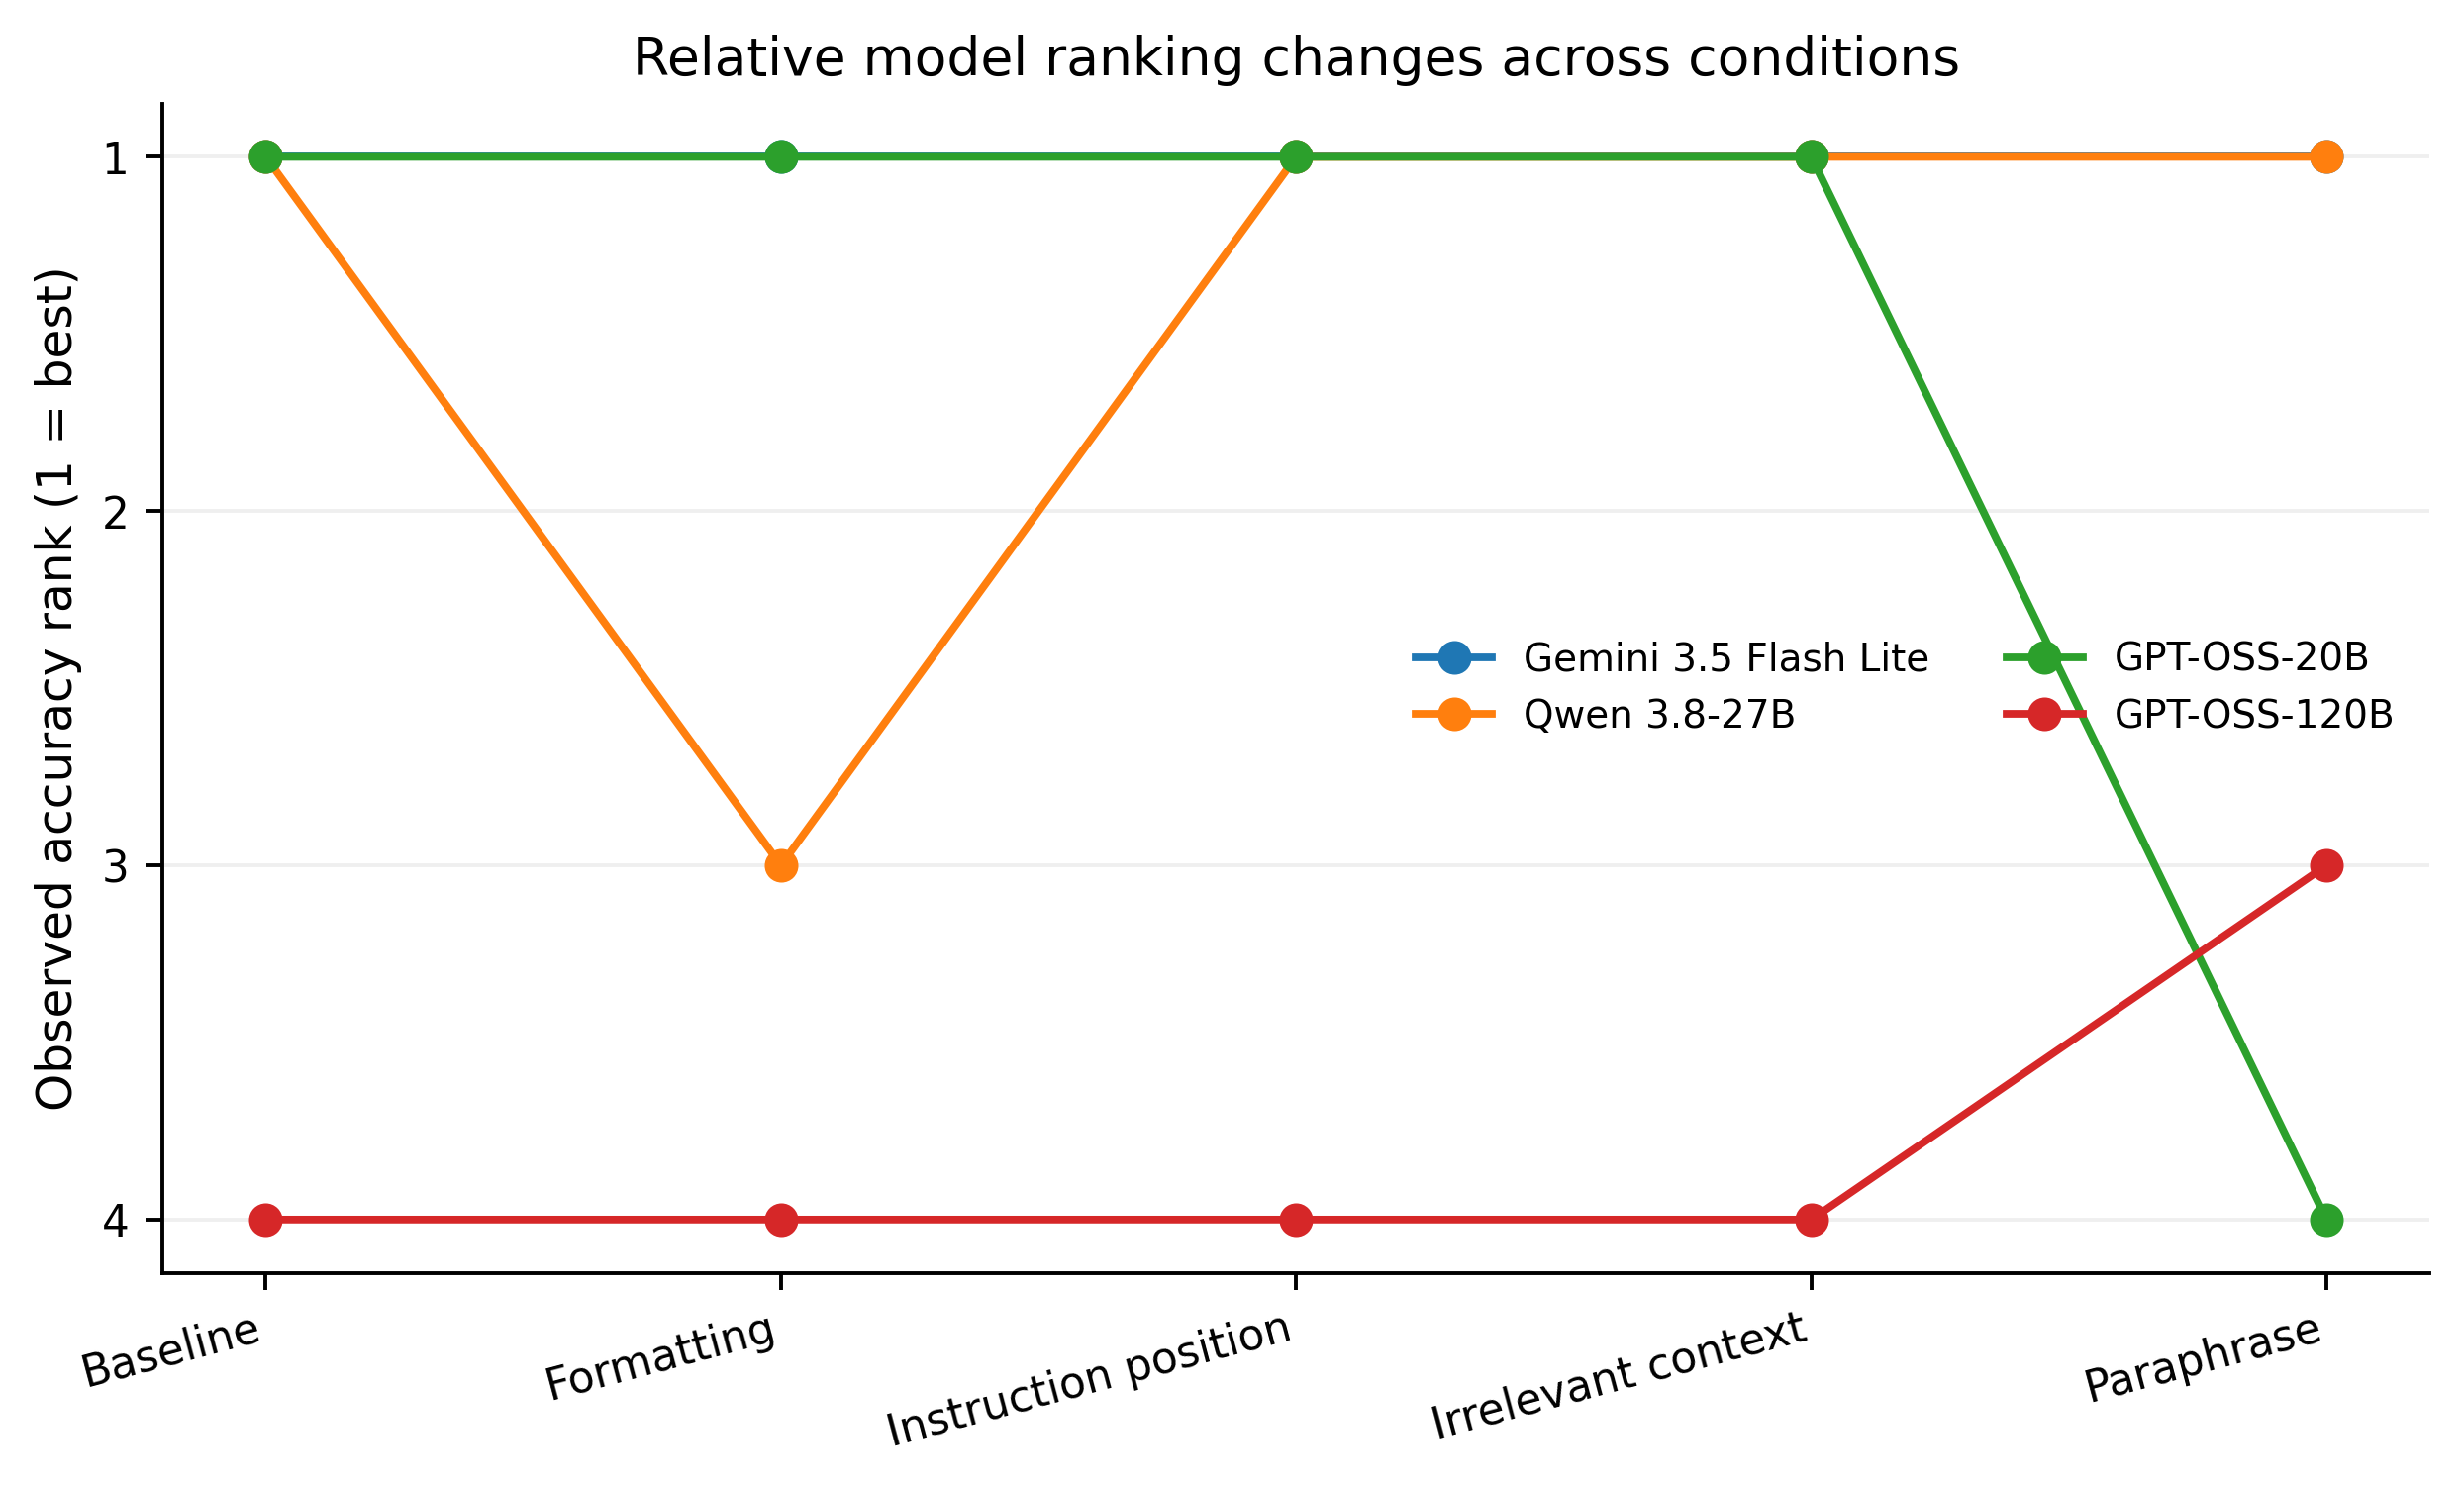

In [6]:
display(Image("../figures/Fig2_condition_dependent_ranking.png"))

**Figure 2.** Observed accuracy rank by condition. Qwen and GPT-OSS-20B are tied at baseline, but their relative performance separates under formatting and paraphrase conditions. This is the Block-A manifestation of the central research question.

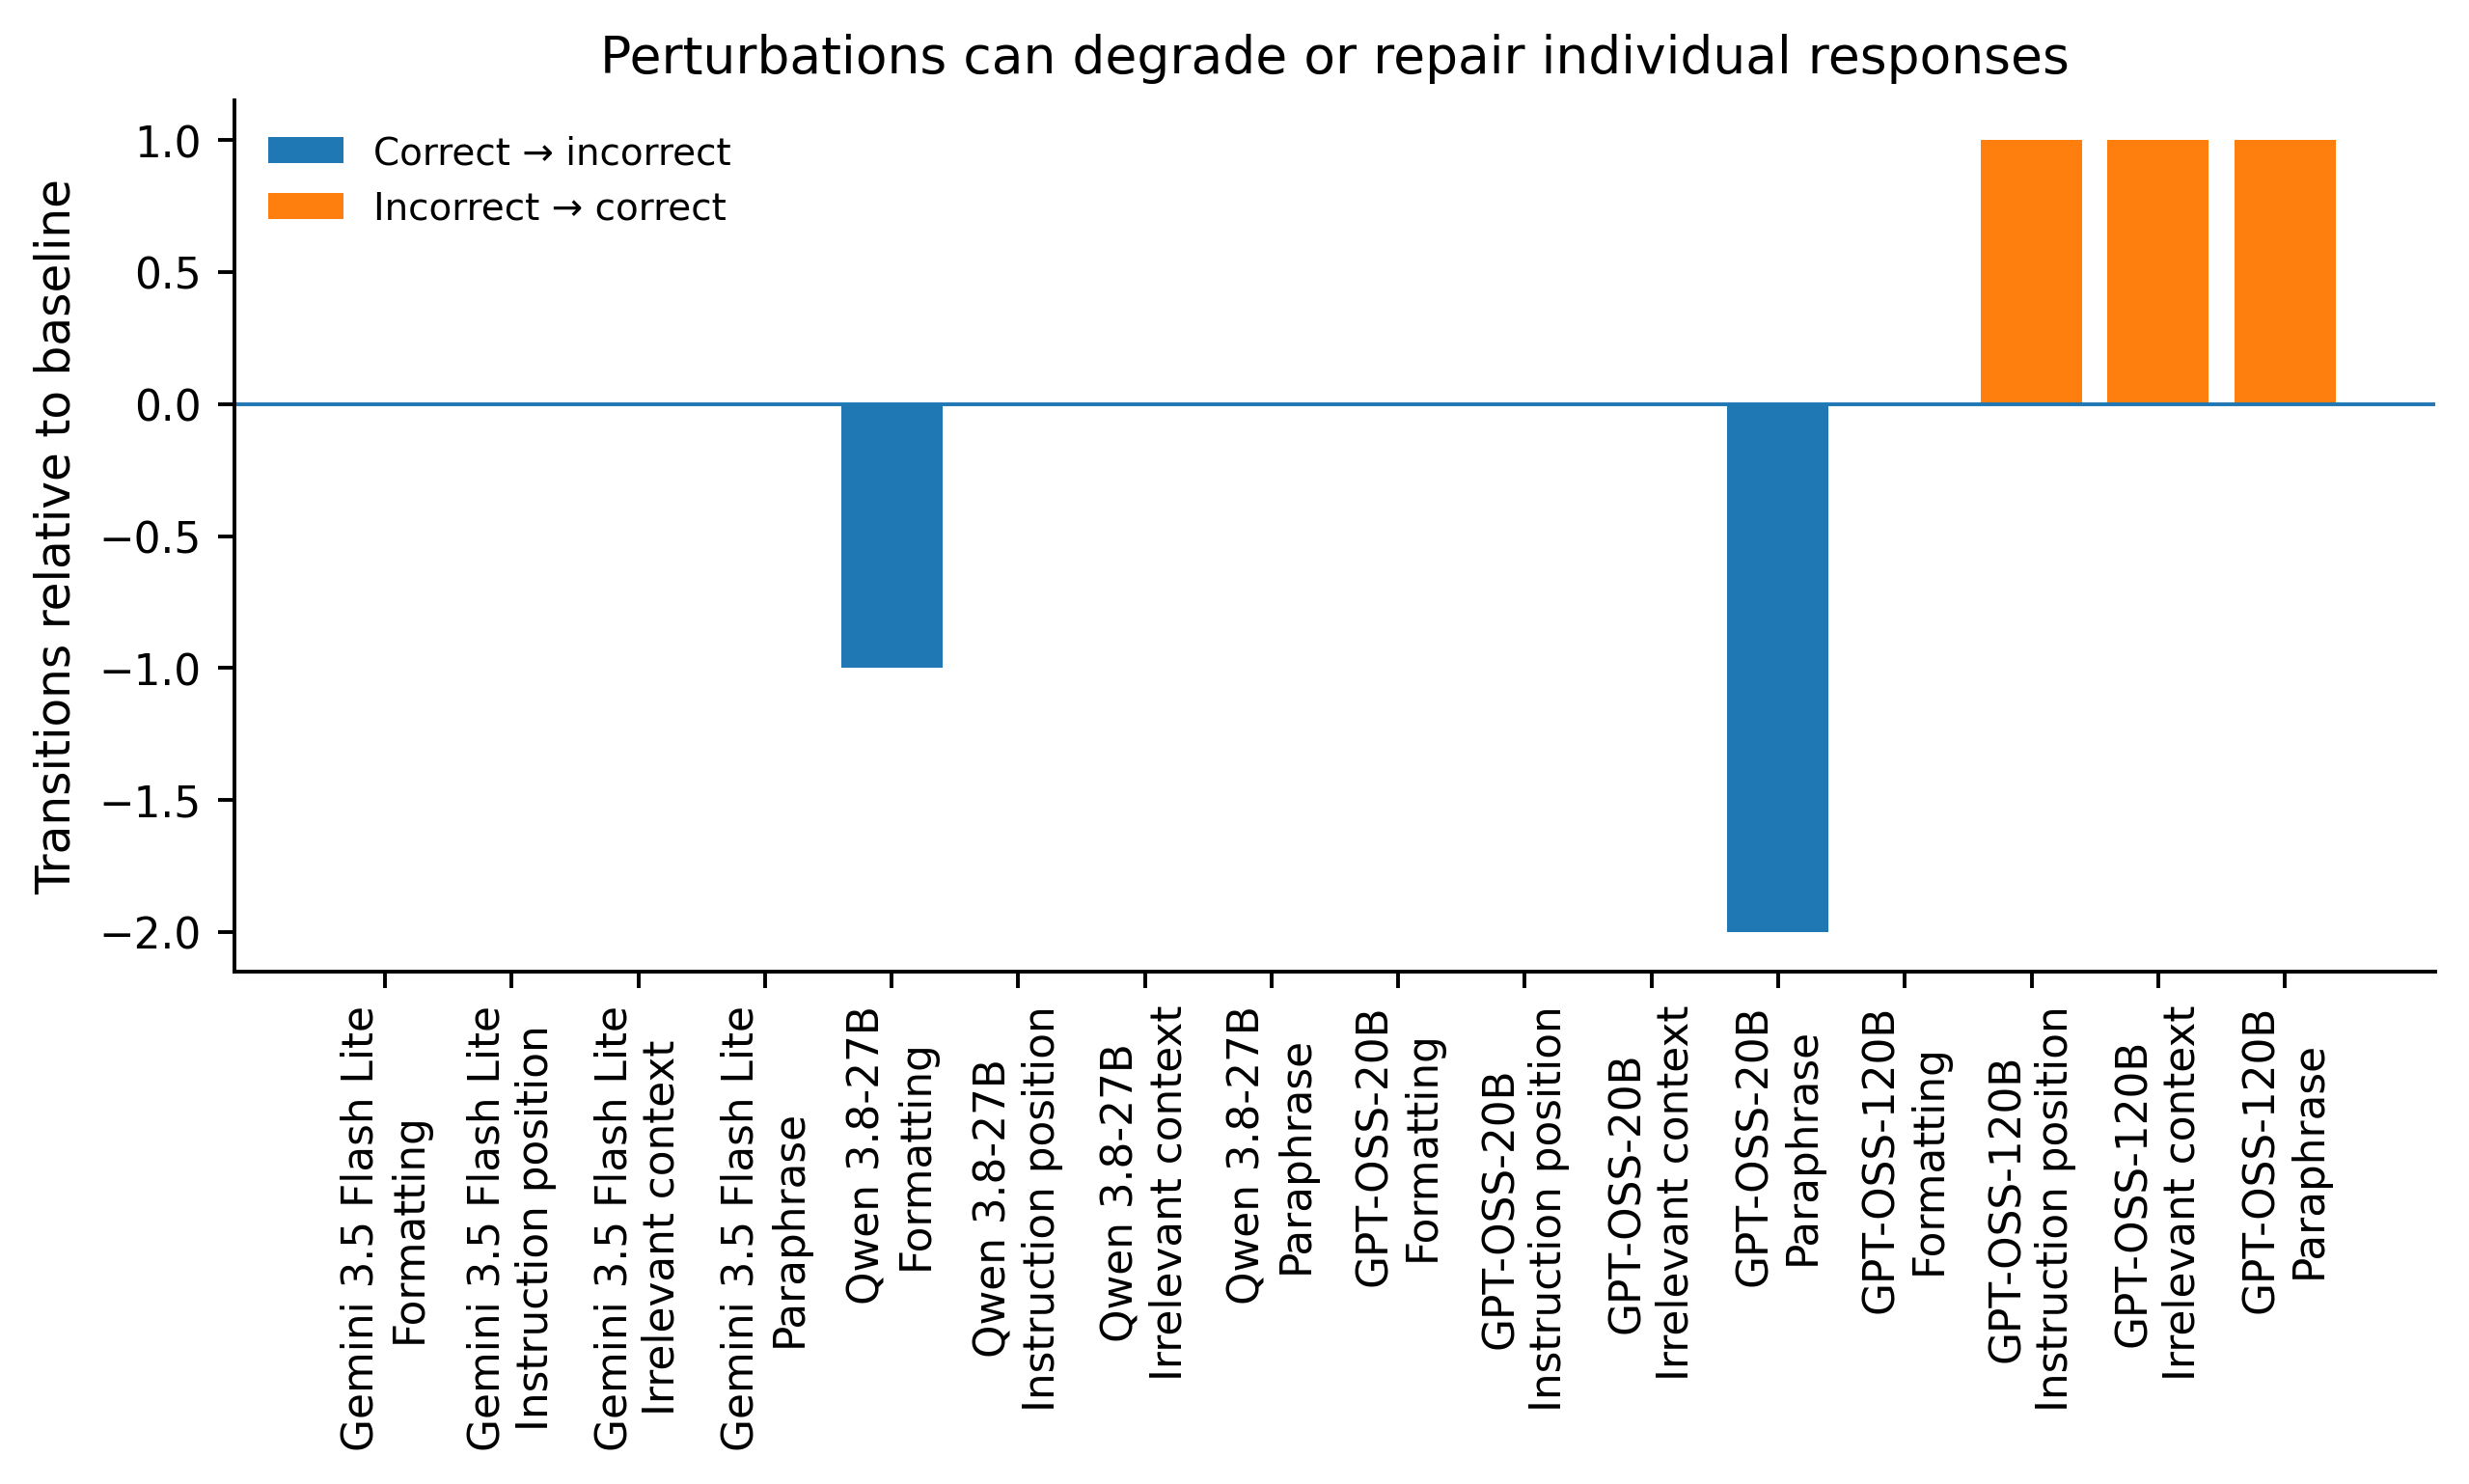

In [7]:
display(Image("../figures/Fig3_baseline_relative_transitions.png"))

**Figure 3.** Paired transitions relative to each model's baseline response on the same source question. Perturbations are not purely destructive: some induce correct→incorrect changes while others repair baseline errors.

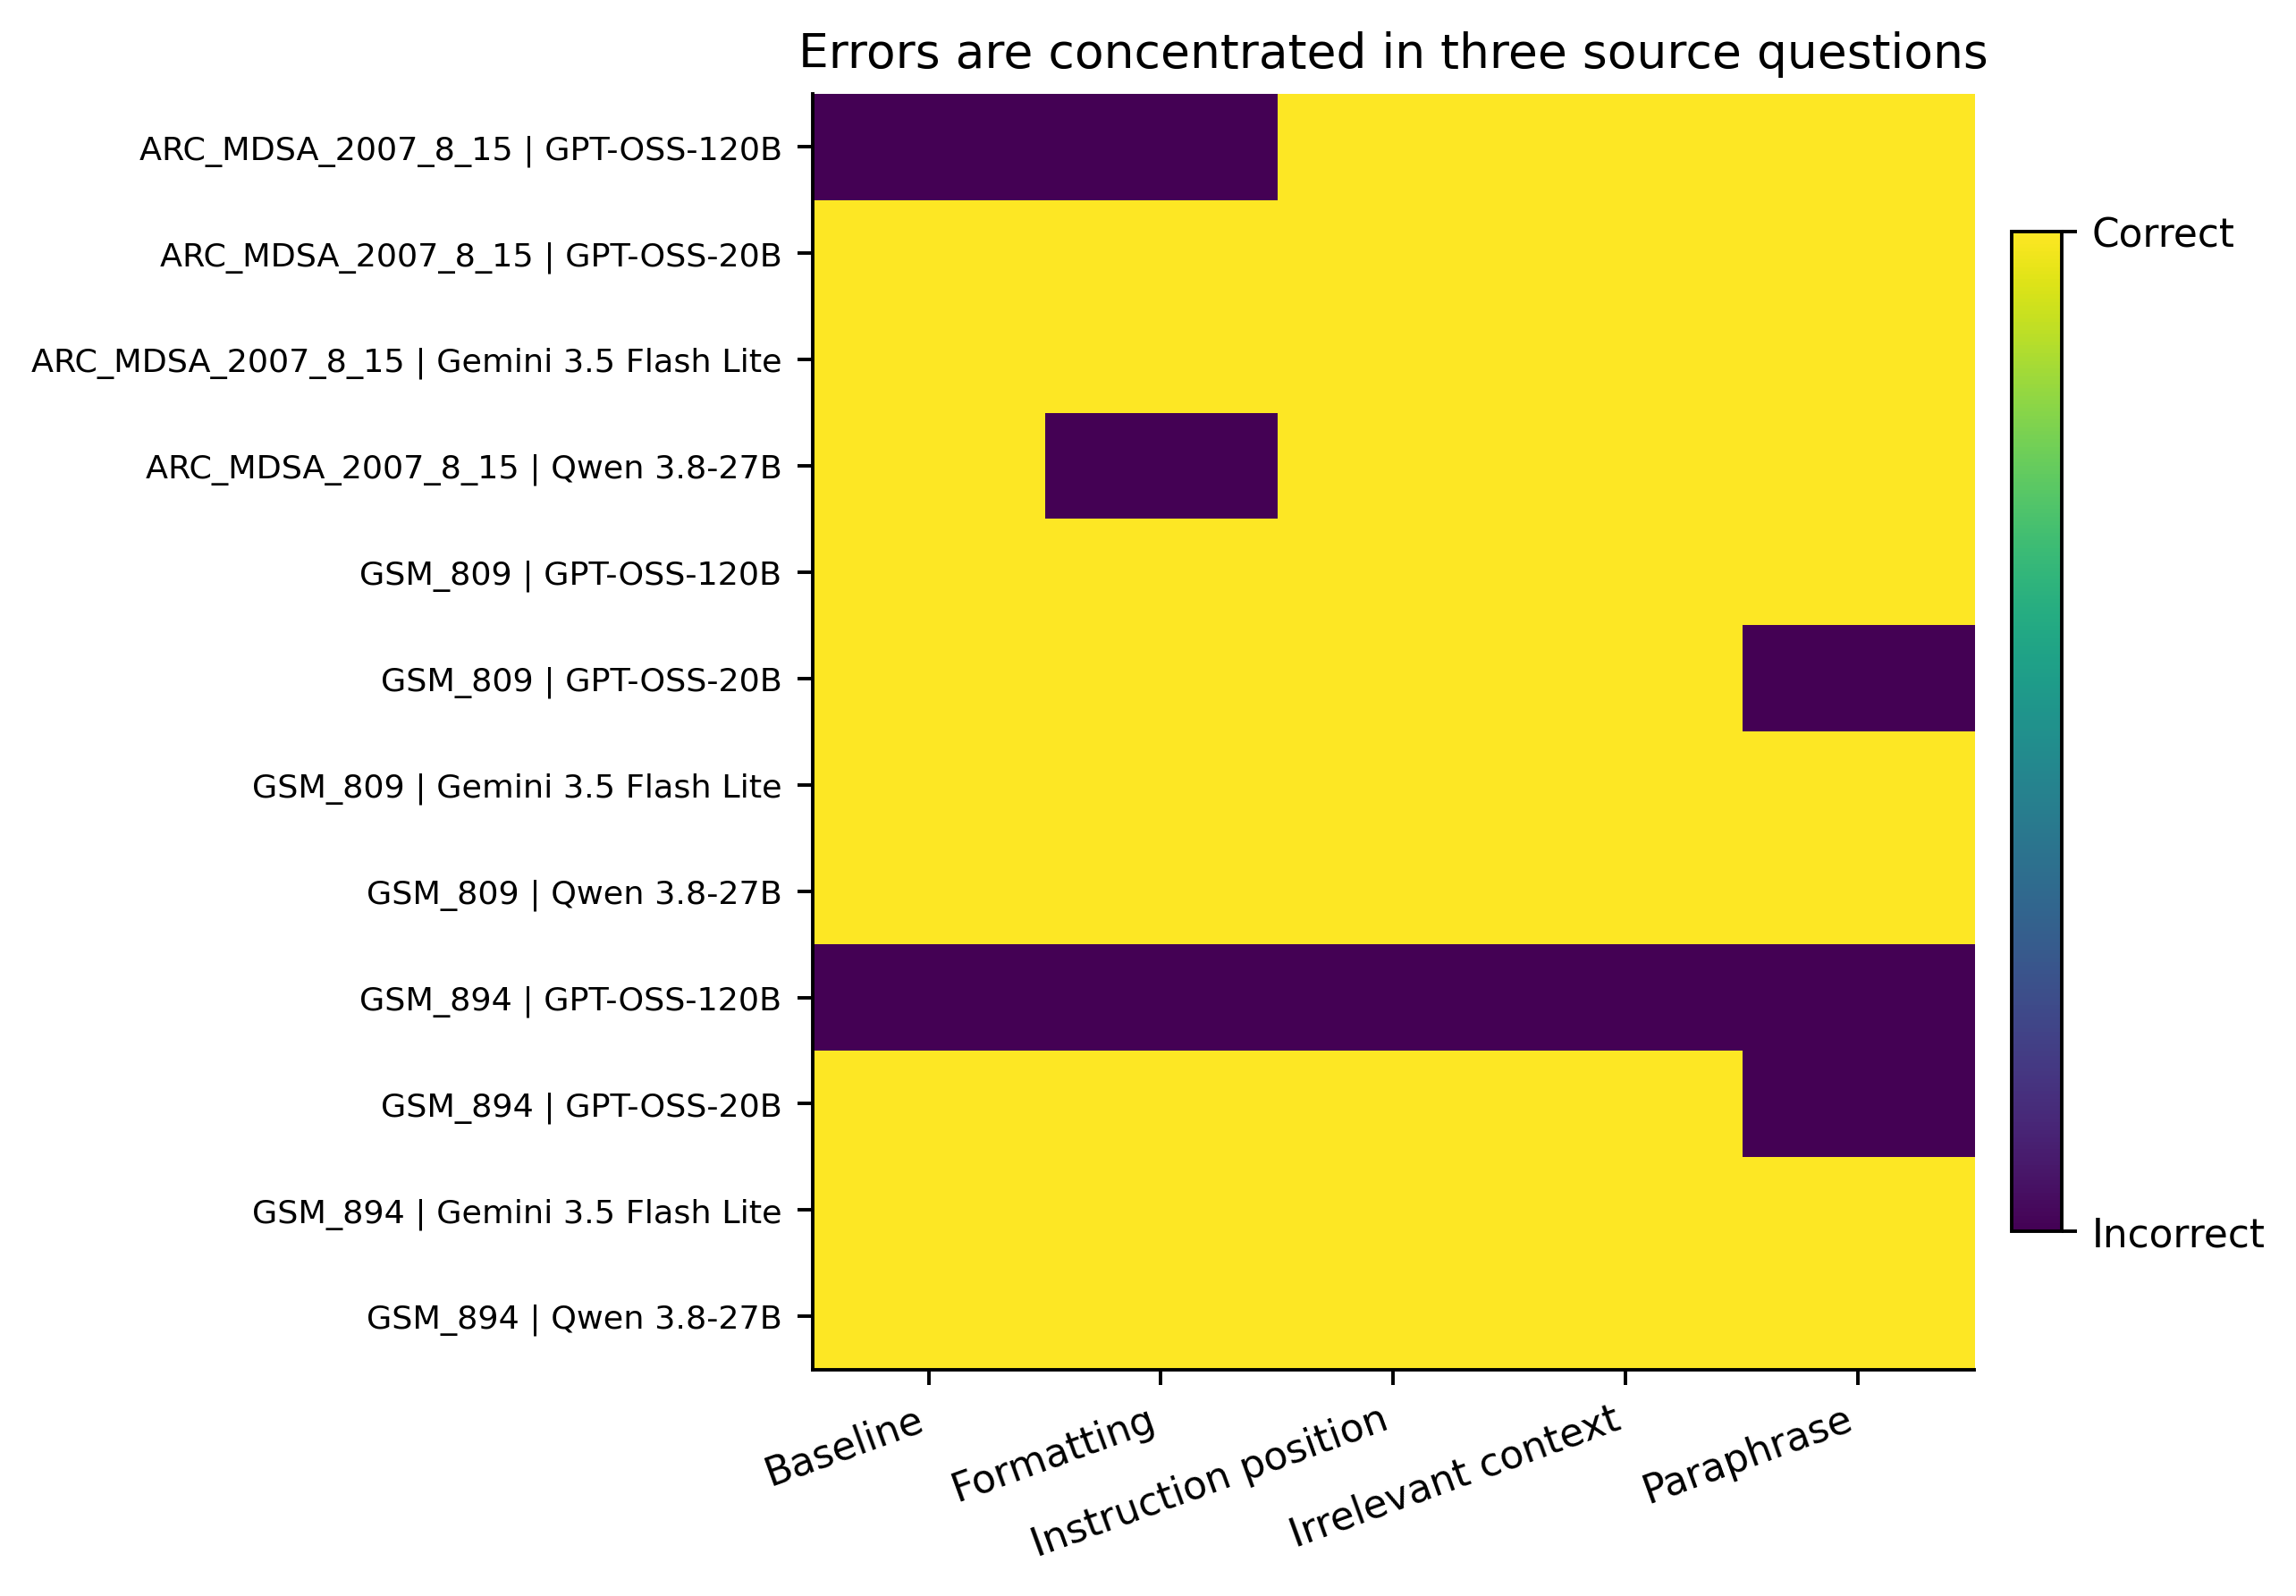

In [8]:
display(Image("../figures/Fig4_error_pattern_heatmap.png"))

**Figure 4.** All ten incorrect observations are concentrated in three source questions. Block A therefore demonstrates structured condition sensitivity but does not yet provide a diverse failure sample for strong predictive modeling.

## 6. Categorical and continuous EDA

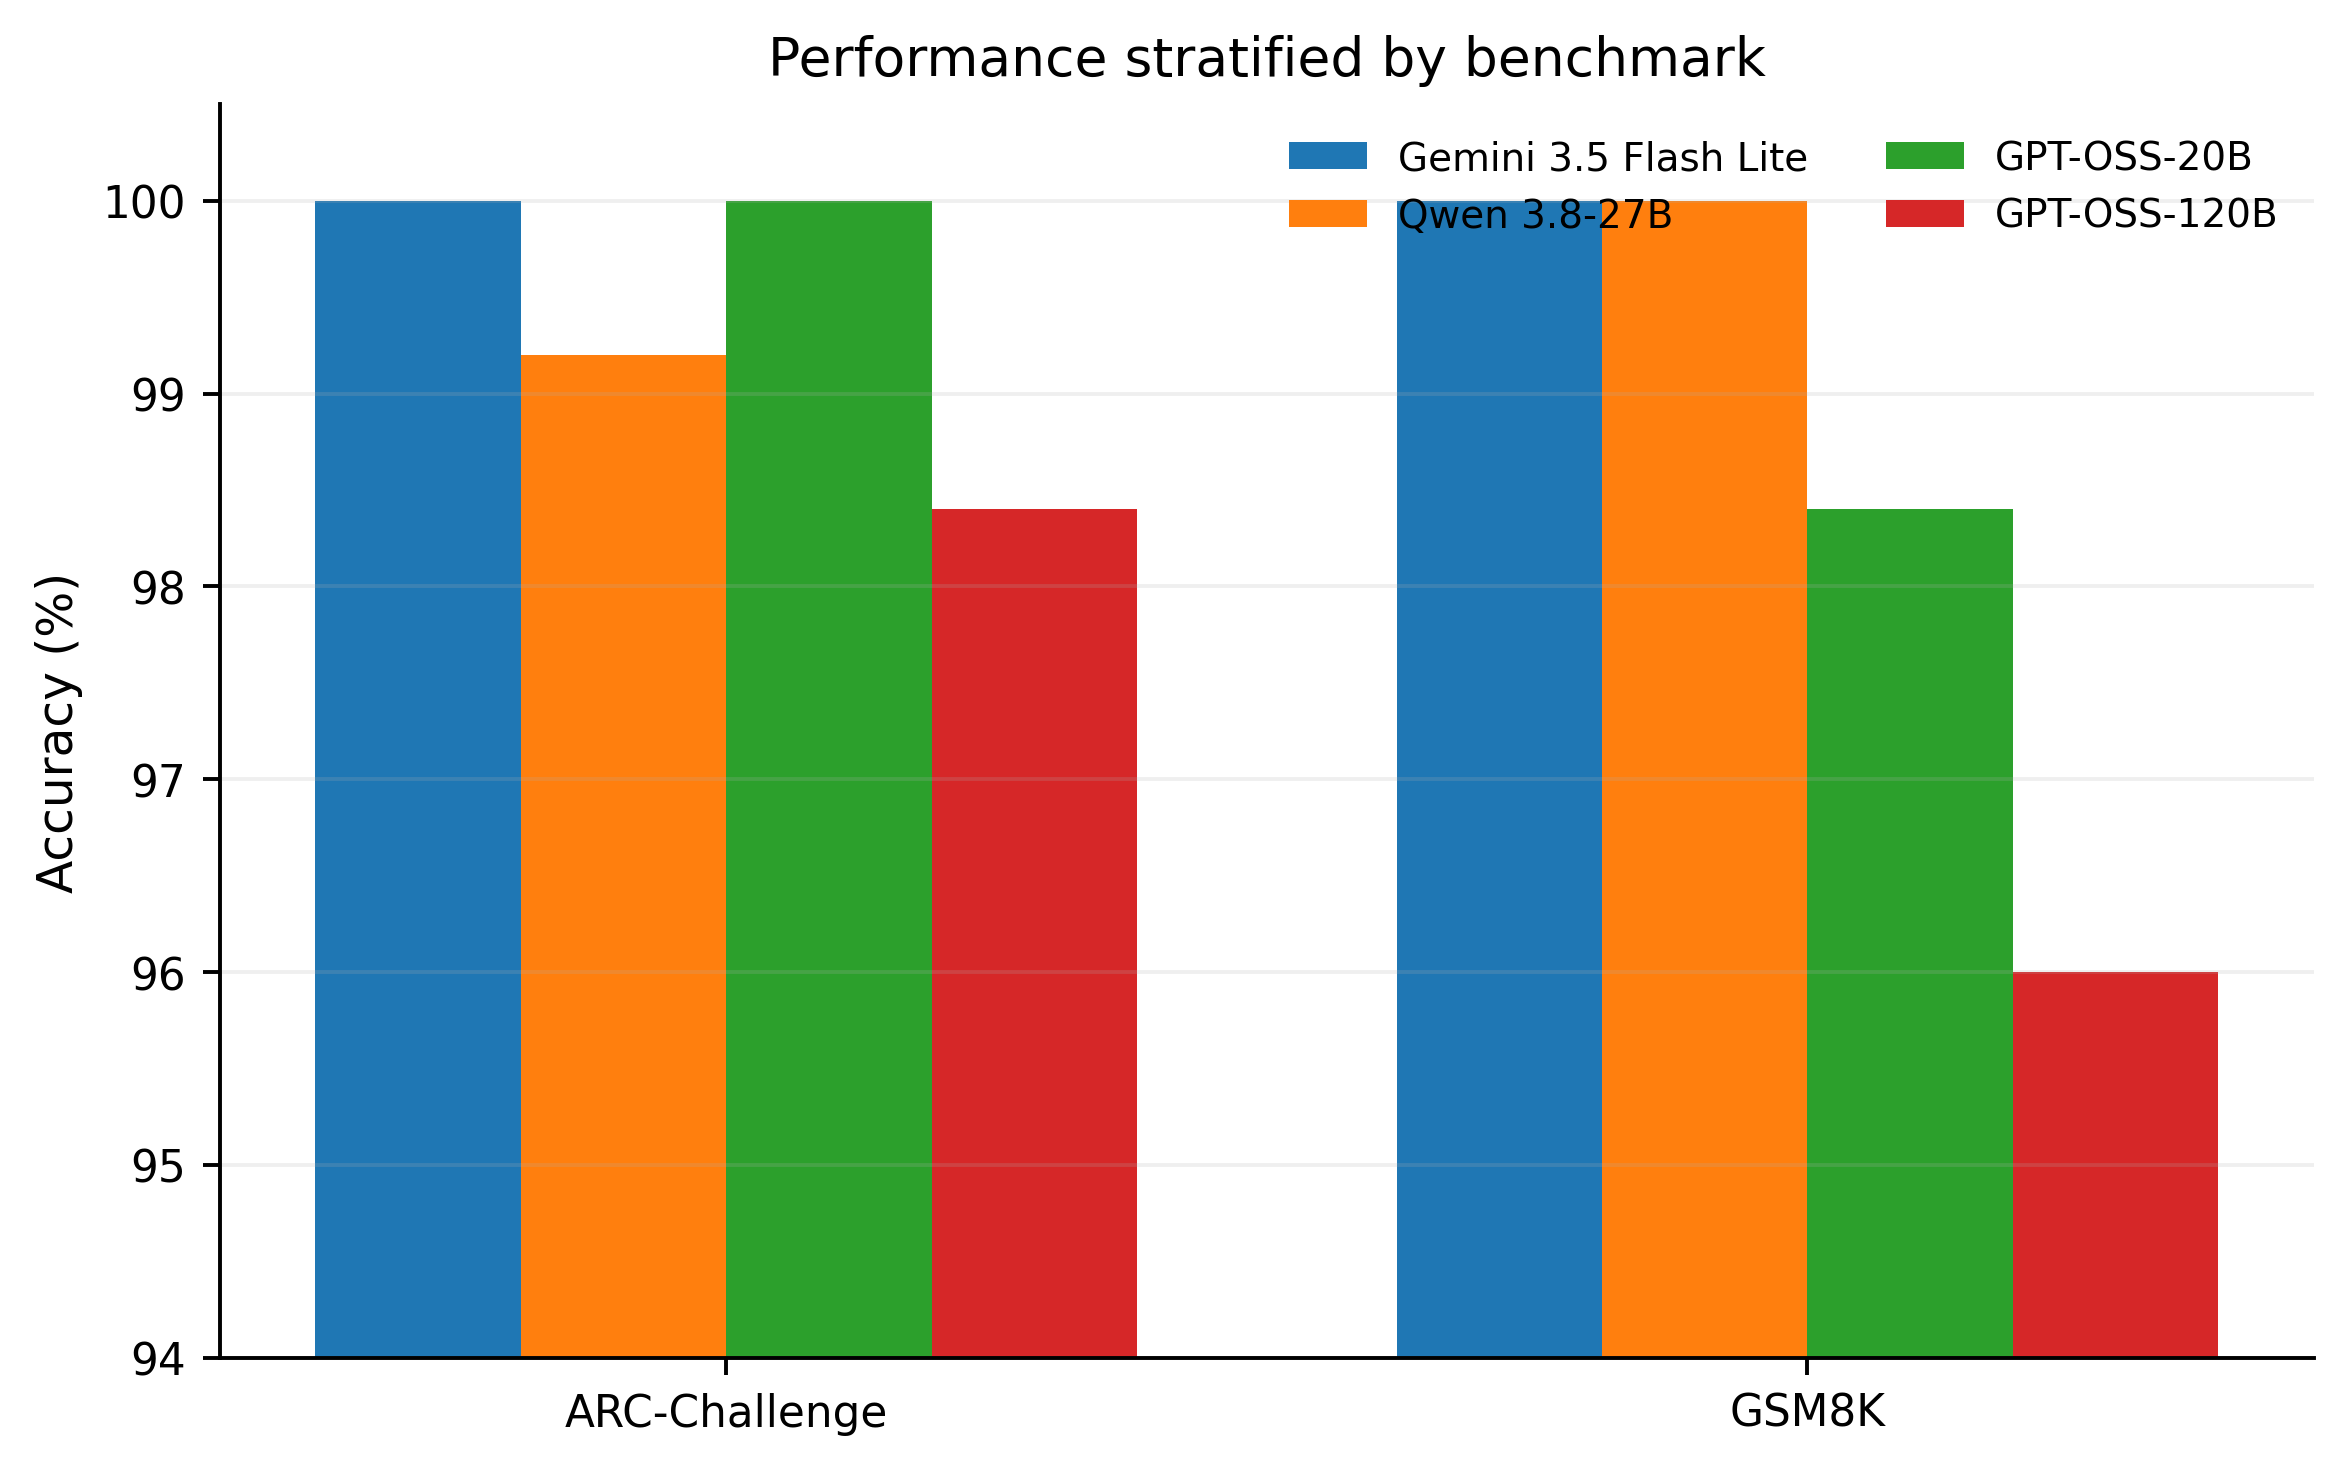

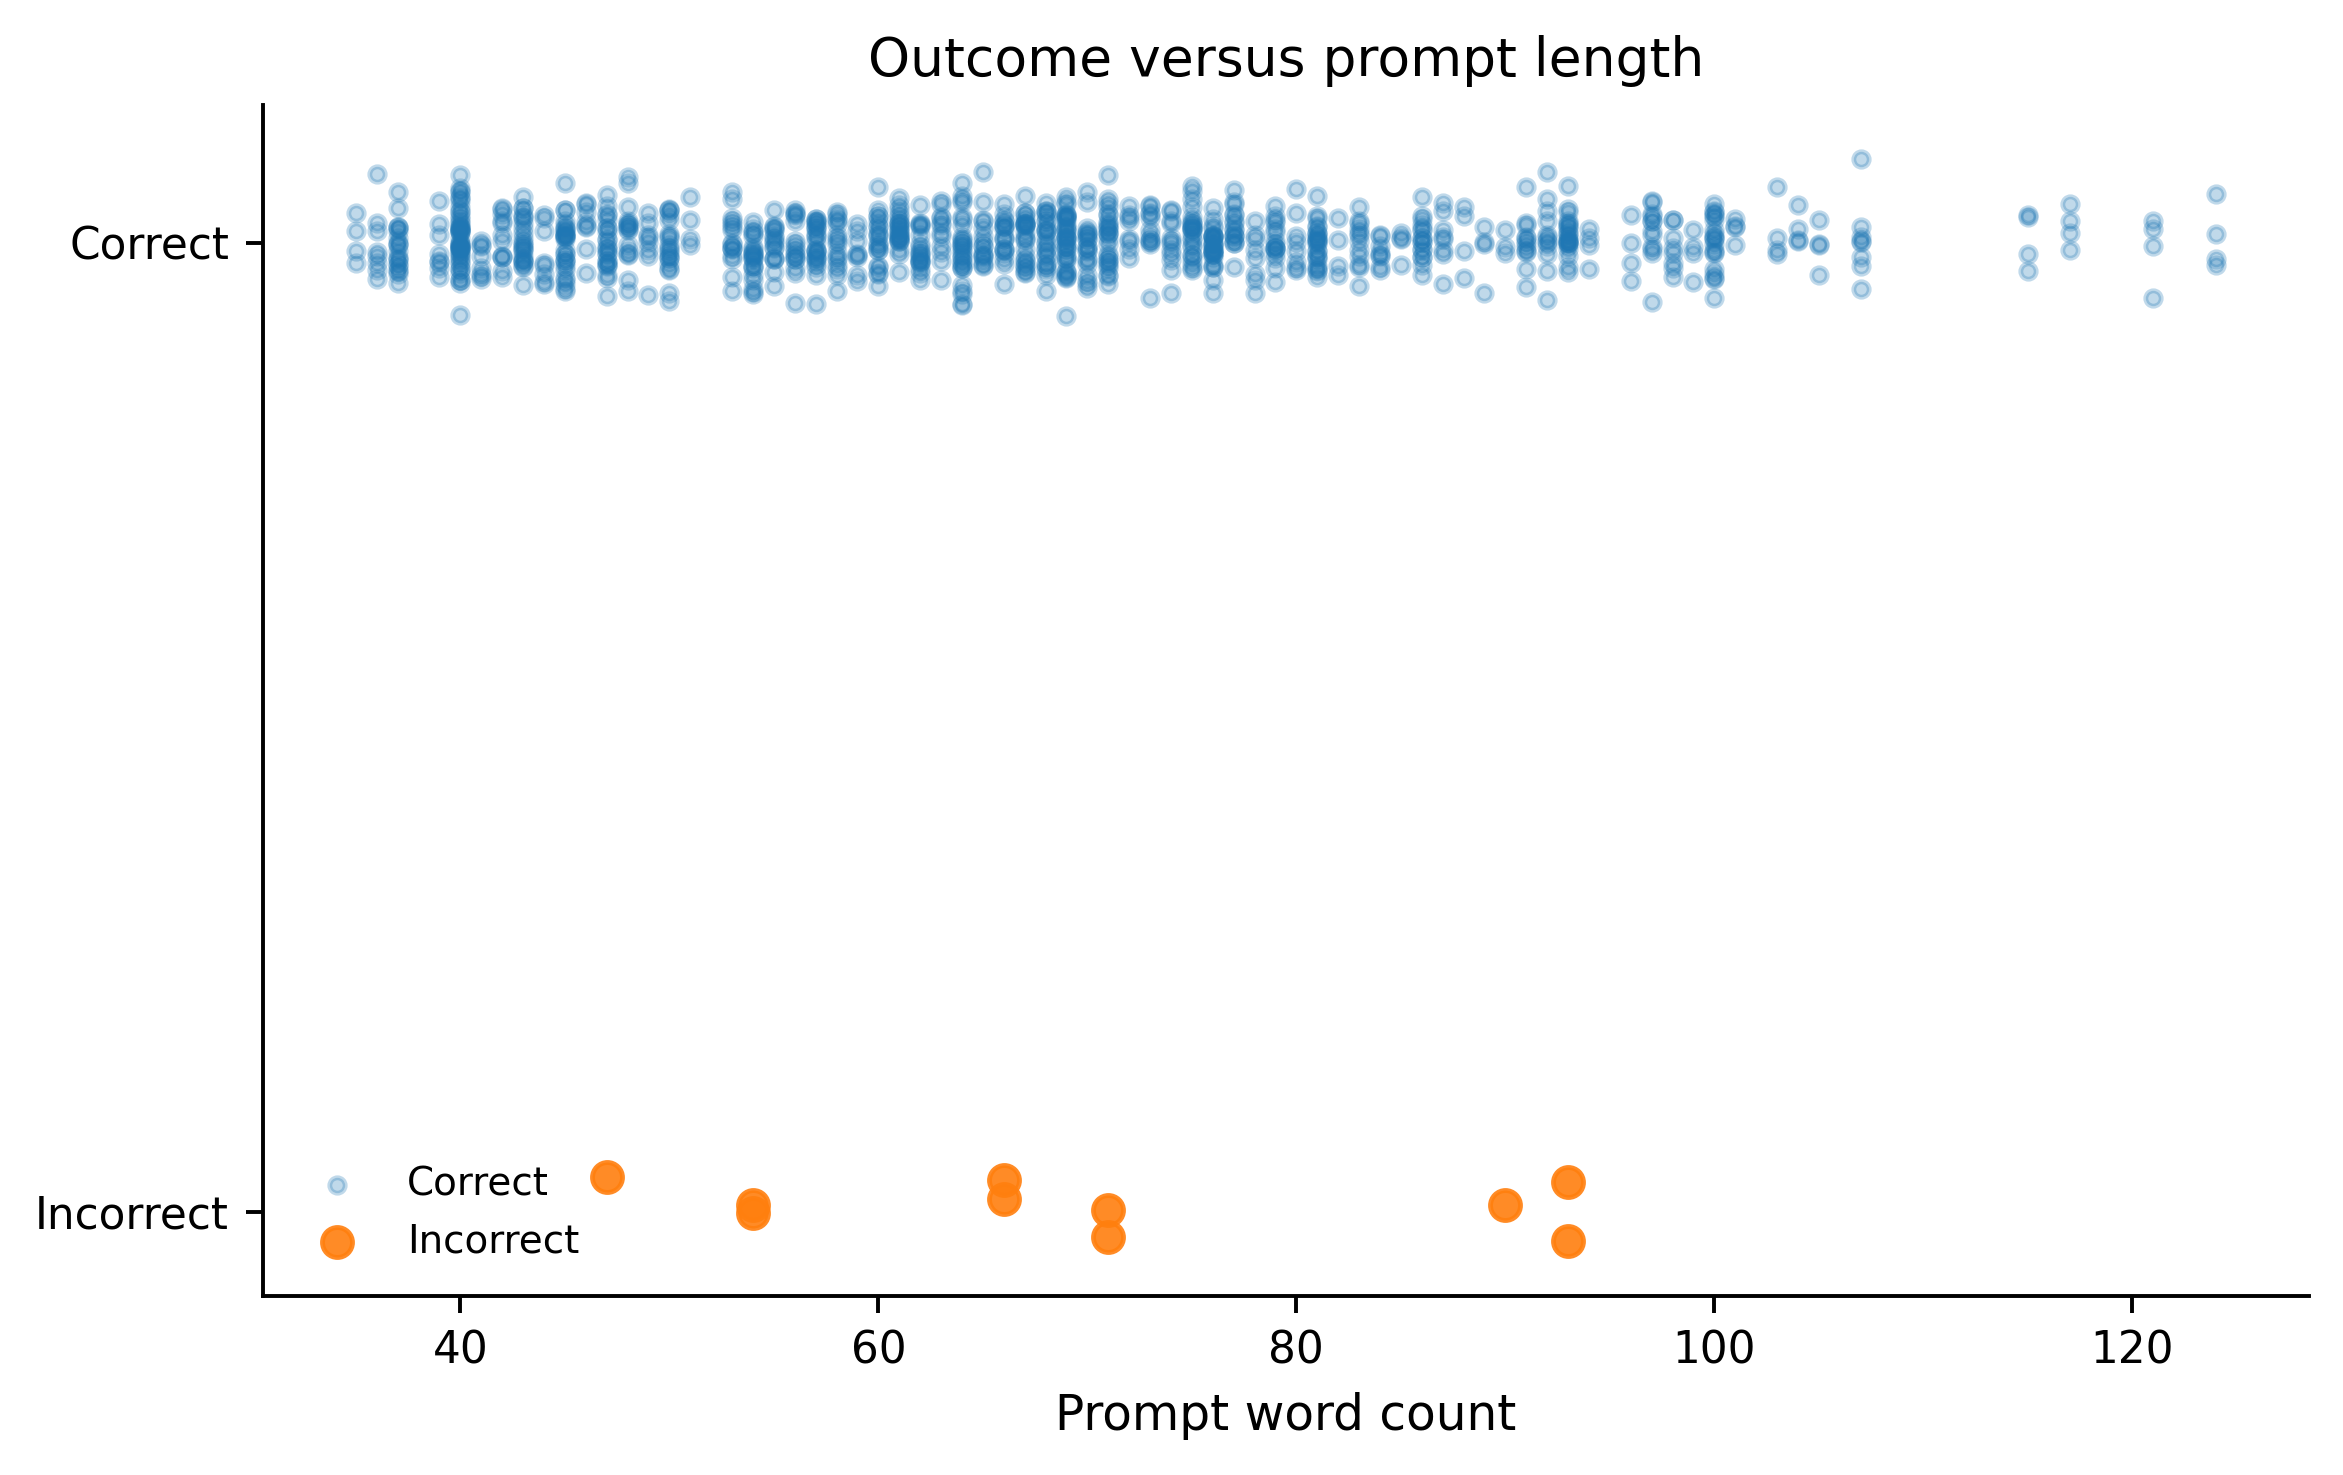

In [9]:
display(Image("../figures/Fig5_benchmark_stratification.png")); display(Image("../figures/Fig6_prompt_length_outcome.png"))

Benchmark stratification provides a categorical comparison; prompt length is a continuous pre-response descriptor. No causal claim is made from prompt length in this high-accuracy initial block.

## 7. Leakage-safe baseline machine-learning model

A class-weighted logistic regression predicts `correct ∈ {0,1}` using model identity, benchmark, condition, prompt word count, and original-question word count. The split is deterministic from `question_id` only, so all models and perturbations of the same source question remain on the same side of the split.

In [10]:
def split_u(q): return int(hashlib.sha256(str(q).encode()).hexdigest()[:8],16)/16**8
qsplit=df[["question_id"]].drop_duplicates().copy()
qsplit["split"]=np.where(qsplit.question_id.map(split_u)<0.20,"test","train")
d=df.drop(columns=["split"],errors="ignore").merge(qsplit,on="question_id")
categorical=["model_tag","benchmark","condition"]; numeric=["prompt_word_count","question_word_count"]
X=d[categorical+numeric]; y=d.correct_int.astype(int); tr=d.split.eq("train"); te=d.split.eq("test")
pre=ColumnTransformer([("cat",OneHotEncoder(handle_unknown="ignore"),categorical),("num",StandardScaler(),numeric)])
clf=Pipeline([("preprocess",pre),("model",LogisticRegression(max_iter=3000,class_weight="balanced",random_state=20261008))])
clf.fit(X[tr],y[tr]); pred=clf.predict(X[te])
print("Train questions:",d.loc[tr,"question_id"].nunique()," Test questions:",d.loc[te,"question_id"].nunique())
print("Train errors:",int((1-y[tr]).sum())," Test errors:",int((1-y[te]).sum()))
print("Accuracy:",round(accuracy_score(y[te],pred),4))
print("Balanced accuracy:",round(balanced_accuracy_score(y[te],pred),4))
print(confusion_matrix(y[te],pred,labels=[0,1]))

Train questions: 37  Test questions: 13
Train errors: 7  Test errors: 3
Accuracy: 0.8654
Balanced accuracy: 0.4377
[[  0   3]
 [ 32 225]]


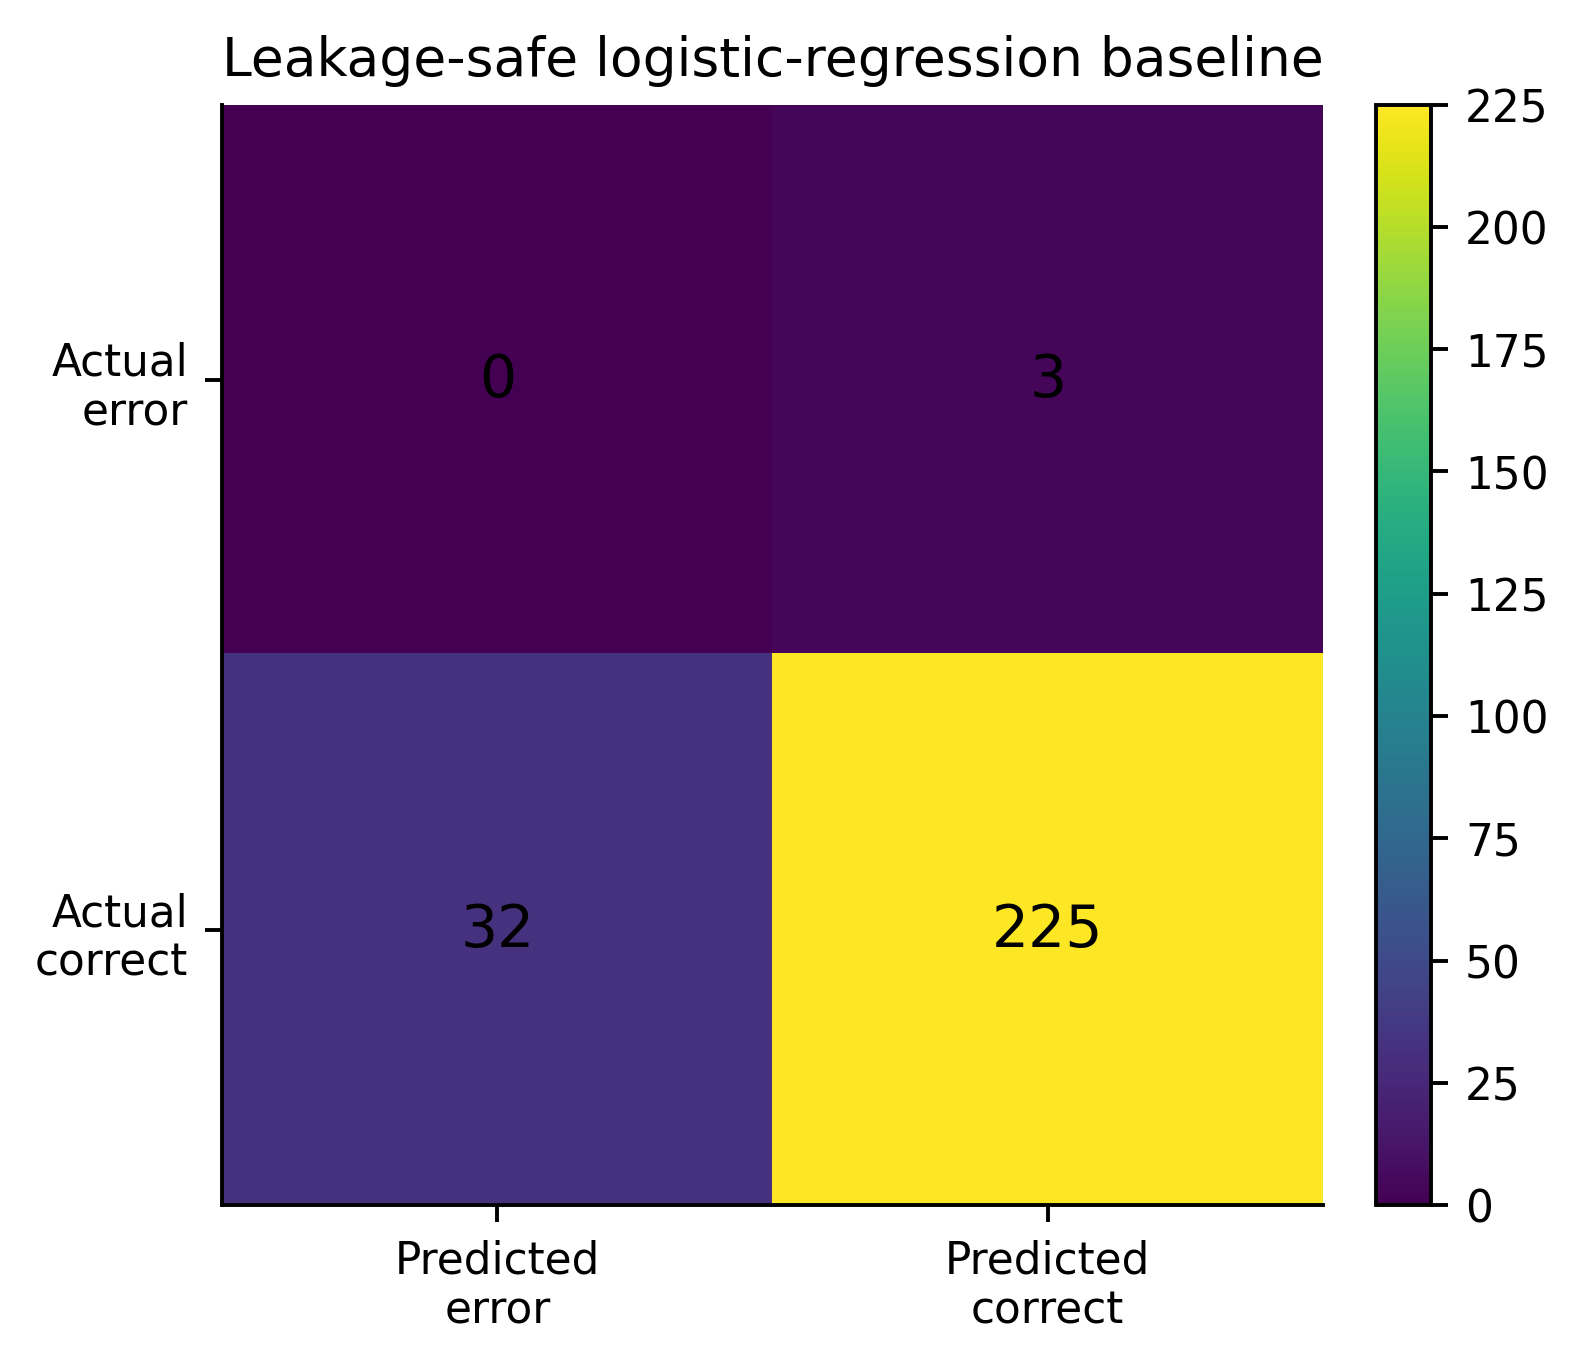

In [11]:
display(Image("../figures/Fig7_logistic_confusion_matrix.png"))

**Figure 7.** The grouped test split contains three errors. The classifier identifies none and produces 32 false error predictions. Ordinary accuracy is 86.5%, but balanced accuracy is 43.8%. With only 10 errors in 1,000 observations, this is appropriately a baseline workflow rather than evidence of reliable failure prediction.

## 8. Initial findings

1. **Aggregate performance is near ceiling but not uniformly stable.** Ten errors occur across 1,000 observations and are concentrated in three source questions.
2. **Perturbation effects are model dependent.** GPT-OSS-20B loses two responses under paraphrase; Qwen loses one under formatting; GPT-OSS-120B also shows perturbations that repair baseline errors.
3. **Relative ranking depends on evaluation condition.** The ordering/ties among models change across baseline, formatting, and paraphrase conditions.
4. **A predictive failure model is premature at Block-A scale.** The leakage-safe logistic baseline cannot reliably identify rare failures, despite high ordinary accuracy.

These findings support the premise that a single aggregate benchmark score can conceal condition-dependent behavior relevant to model selection.

## 9. Limitations and M24 next steps

Block A contains only 50 source questions and ten incorrect model-condition observations. The observed ranking changes are descriptive rather than population-level claims. The experiment was designed in advance with frozen Blocks B–D. M24 will expand the sample without redefining prompts or questions after observing Block-A outcomes, enabling uncertainty estimates, paired statistical tests, richer robustness descriptors, and stronger supervised models.